# QA_max_cut_lib · current CPU API guide

Version **0.1.0rc2**. This notebook covers the functionality implemented across the four CPU stages, including base RQAOA and analytic p=1. The complete target feature set lives in the agreed architecture and migration status.

Plan: graphs → exact reference → QAOA circuit and criteria → budget → results and saving → visualization → landscapes. Seeds are fixed for reproducibility. For export, every full pass through the notebook creates a new explicitly named folder.

Install with `python -m pip install -e ".[cpu,notebooks]"` from the project root and select its Python kernel. All cells are designed to run sequentially without NVIDIA hardware and without a system TeX installation.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from copy import deepcopy
import json
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
from QA_max_cut_lib import WeightedGraph, GraphFactory, SolverFactory, ExactCPU, QAOACPU
from QA_max_cut_lib.generators import partition
from QA_max_cut_lib import tools
from QA_max_cut_lib.solvers.objectives import validate_objective, objective_value

root = Path.cwd() if (Path.cwd() / 'configs').is_dir() else Path.cwd().parent
export_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
output_dir = root / 'notebooks' / '_outputs' / ('guide_' + export_id)
style = {'text_engine': 'mathtext', 'figsize': [10, 6]}
print('Available solvers:', SolverFactory.available())

Available solvers: ('exact_cpu', 'qaoa_cpu', 'rqaoa_cpu')


## 1. Problem and source labels

$$C(s)=\sum_{(i,j)\in E}w_{ij}(1-s_i s_j)/2,\qquad E(s)=-C(s).$$

The constant part of the energy is not dropped. Vertices carry integer labels with arbitrary gaps, including negative ones. An isolated vertex must still receive a spin. A zero edge is kept in the structure, and a negative edge keeps its sign in the objective.

Node order: (10, 30, 80, -7, 101)
Weighted edges: ((10, 30, 1.5), (30, 80, -0.5), (10, 80, 2.0), (-7, 80, 0.75))
Manual C: 4.25 E: -4.25


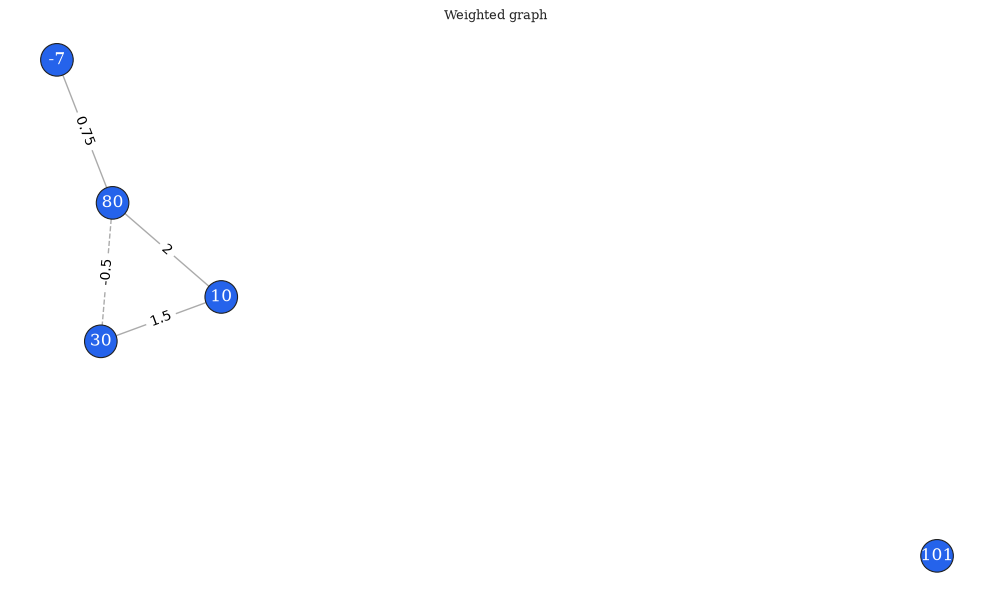

In [2]:
graph = WeightedGraph(
    [(10, 30, 1.5), (30, 80, -0.5), (10, 80, 2.0), (80, -7, 0.75)],
    nodes=[10, 30, 80, -7, 101],
)
print('Node order:', graph.nodes)
print('Weighted edges:', graph.edges)
manual = {10: 1, 30: -1, 80: -1, -7: 1, 101: 1}
print('Manual C:', graph.cut_value(manual), 'E:', -graph.cut_value(manual))
figure = tools.plot_graph(graph, {'style': style})
display(figure)
plt.close(figure)

## 2. Graph edits, subgraphs and partitioning

Edits are applied to the existing object. `subgraph` builds an induced subgraph without changing external labels. `partition` splits vertices randomly; cross-partition edges are excluded from the subgraphs, so the solutions of the parts do not by themselves solve the original problem.

In [3]:
editable = graph.copy()
before = editable.snapshot()['fingerprint']
editable.set_weight(10, 30, 2.25)
editable.add_node(500)
editable.set_weight(101, 500, 0.0)
editable.remove_edge(101, 500)
assert editable.snapshot()['fingerprint'] != before
small = editable.subgraph([80, 10, 101])
parts = partition(editable, 2, seed=3)
print('Subgraph:', small.nodes, small.edges)
print('Partition:', [part.nodes for part in parts])
snapshot = editable.snapshot()
assert WeightedGraph.from_snapshot(snapshot).snapshot() == snapshot

Subgraph: (80, 10, 101) ((10, 80, 2.0),)
Partition: [(80, 500), (101, 30), (-7, 10)]


## 3. All implemented recipes

Topology: Complete, G(n,m), Erdős–Rényi G(n,p). Weights: constant, equiprobable list or uniform interval. Separate seeds are stored in both the recipe and the snapshot. Support for a 1000-vertex graph concerns representation and generation; direct full QAOA has an exponential state size and a small guard limit.

In [4]:
recipes = [
    {'type': 'complete', 'seed': 7, 'parameters': {'n_vertices': 5},
     'weights': {'type': 'constant', 'parameters': {'value': 1.0}, 'seed': 8}},
    {'type': 'gnm', 'seed': 7, 'parameters': {'n_vertices': 5, 'n_edges': 4},
     'weights': {'type': 'signed_discrete', 'parameters': {'values': [-1., 1.]}, 'seed': 8}},
    {'type': 'erdos_renyi', 'seed': 7, 'parameters': {'n_vertices': 5, 'probability': .4},
     'weights': {'type': 'uniform', 'parameters': {'low': -1., 'high': 2.}, 'seed': 8}},
]
for recipe in recipes:
    generated = GraphFactory.from_recipe(recipe)
    repeated = GraphFactory.from_recipe(recipe)
    assert generated.snapshot() == repeated.snapshot()
    print(recipe['type'], len(generated), 'nodes;', len(generated.edges), 'edges')

complete 5 nodes; 10 edges
gnm 5 nodes; 4 edges
erdos_renyi 5 nodes; 3 edges


## 4. ExactCPU and normalized quality

Enumeration fixes the first spin to +1 via the global inversion, then restores the full number of degenerate maxima. Two passes avoid storing every cost: first the extrema, then an exact count relative to the maximum found. This is brute force in float64, not symbolic arithmetic.

`quality_score=(C−C_min)/(C_max−C_min)` is appropriate for signed weights when both extrema of **the same graph** are known. A zero range returns None.

In [5]:
reference = ExactCPU({'parameters': {'batch_size': 16}, 'output': {'color': 'never'}})
reference.solve(graph, report=1, logs=0, num_treads=1)
print('C_max:', reference.cut_value, 'C_min:', reference.worst_cut_value)
print('Optimal assignments:', reference.optimal_count)
print('Evaluations in two passes:', reference.states_evaluated)
print('Manual solution quality:', tools.quality_score(
    graph.cut_value(manual), reference.cut_value, reference.worst_cut_value))

QA_max_cut_lib | exact_cpu | completed
Cut: 4.25   Energy: -4.25   Time: 0.0009 s
Resources: {"num_stages": 2, "num_treads": 1, "shots_used": 0, "states_evaluated": 32}
C_max: 4.25 C_min: 0.0
Optimal assignments: 4
Evaluations in two passes: 32
Manual solution quality: 1.0


## 5. QAOA circuit and the sign of the energy

Initial state $|+\rangle^N$. In each layer $\exp(-i\gamma H_E)=\exp(+i\gamma C)$ acts first, then $\exp(-i\beta\sum_iX_i)$. Angle order: all $\gamma$, then all $\beta$.

For a single edge w=1 we get $\langle C\rangle=[1-\sin\gamma\sin(4\beta)]/2$. Check the analytic point: $\gamma=-\pi/2$, $\beta=\pi/8$. State collection is enabled explicitly; zero training length means a readout of the supplied angles.

In [6]:
edge = WeightedGraph([(7, 20, 1.0)])
analytic = QAOACPU({
    'seed': 1,
    'optimizer': {'parameters': {'max_steps': 0}},
    'initialization': {'type': 'fixed_angles', 'parameters': {'values': [-np.pi/2, np.pi/8]}},
    'collect': {'probabilities': True, 'statevector': True, 'correlations': True},
})
analytic.solve(edge)
assert np.isclose(analytic.expected_energy, -1.0)
assert np.isclose(np.vdot(analytic.statevector, analytic.statevector), 1.0)
assert np.isclose(analytic.correlations[0, 1], -1.0)
assert analytic.objective_value is None
print('Expected E:', analytic.expected_energy)
print('Probabilities:', analytic.probabilities)
print('Physical correlations:', analytic.correlations)

Expected E: -1.0
Probabilities: [3.55016284e-33 5.00000000e-01 5.00000000e-01 3.55016284e-33]
Physical correlations: [[ 1. -1.]
 [-1.  1.]]


## 6. Five criteria: F is maximized, L=−F is minimized

Mean Cut gives $L=\langle E\rangle$. CVaR averages the best α fraction of the probability mass, splitting the boundary state. Gibbs is $\log\langle e^{\eta C}\rangle/\eta$. Best-of-K is the expectation of the best of K independent C values. Threshold Probability is $P(C\ge A)=P(E\le-A)$.

For the last four, `optimizer_loss` cannot automatically be called the ordinary mean physical energy. Threshold probability is dimensionless. We first check the criteria on one known distributed random variable, then run independent QAOA runs.

In [7]:
objectives = [
    {'type': 'mean_cut', 'parameters': {}},
    {'type': 'cvar', 'parameters': {'alpha': .5}},
    {'type': 'gibbs', 'parameters': {'eta': .7}},
    {'type': 'best_of_k', 'parameters': {'k': 3}},
    {'type': 'threshold_probability', 'parameters': {'threshold': 2.5}},
]
cuts = np.array([-2., 0., 3.])
masses = np.array([.2, .3, .5])
for objective in objectives:
    resolved = validate_objective(objective)
    print(objective['type'], 'F =', round(objective_value(cuts, masses, resolved), 6))

criterion_runs = []
for objective in objectives:
    solver = QAOACPU({'seed': 4, 'objective': objective,
                     'optimizer': {'parameters': {'max_steps': 8}},
                     'readout': {'mode': 'best_of_shots', 'shots': 64}})
    solver.solve(graph)
    criterion_runs.append(solver.last_run)
    print(objective['type'], 'L =', round(solver.optimizer_loss, 6),
          'solution E =', solver.solution_energy)

mean_cut F = 1.1
cvar F = 3.0
gibbs F = 2.12706
best_of_k F = 2.609
threshold_probability F = 0.5
mean_cut L = -2.008015 solution E = -4.25
cvar L = -3.196381 solution E = -4.25
gibbs L = -2.710943 solution E = -4.25
best_of_k L = -3.250886 solution E = -4.25
threshold_probability L = -0.289445 solution E = -4.25


## 7. Multi-layer optimization and accumulation

ADAM receives central differences of the loss function. With p layers there are d=2p parameters; one full step needs 2d+1 evaluations. The step history holds the centers, while the detailed history also holds the gradient probes. The final solution uses the best already-evaluated angles, so `optimal_angles` may come from a probe rather than from the step center.

Here we use p=2 and complex64. Small differences relative to complex128 are the expected numerical error. All large outputs are enabled separately via collect.

Angles [gamma0, gamma1, beta0, beta1]:

[ 2.46099336 -1.83819702  0.03578953 -0.48066864]
State dtype: complex64
History rows: 20 180


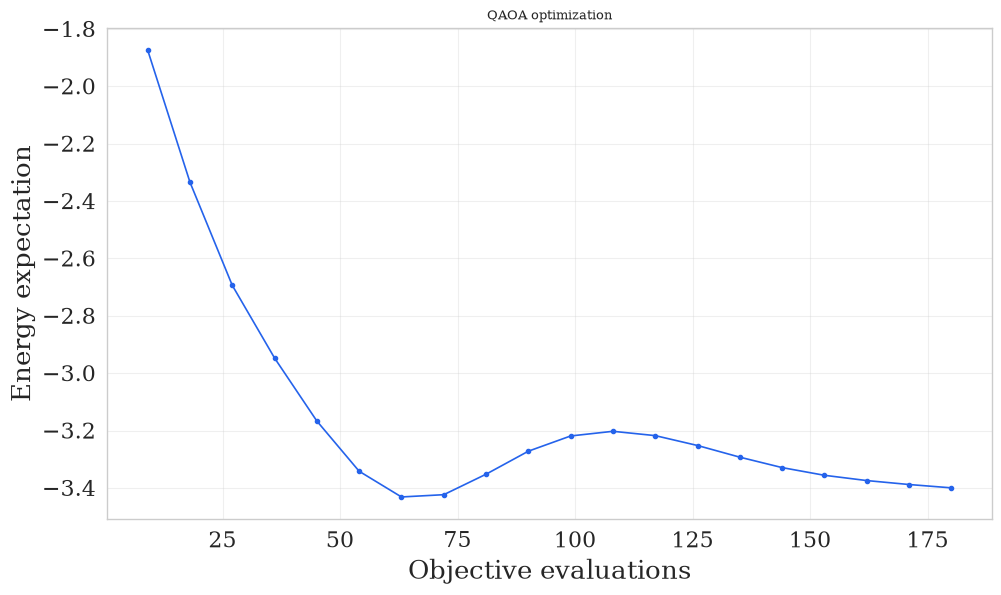

In [8]:
training_config = {
    'type': 'qaoa_cpu', 'seed': 17, 'num_treads': 1,
    'parameters': {'layers': 2, 'dtype': 'complex64'},
    'initialization': {'type': 'random_angles'},
    'optimizer': {'parameters': {'max_steps': 20, 'learning_rate': .05},
                  'gradient': {'type': 'central_difference', 'parameters': {'step': .02}}},
    'collect': {'optimizer_history': True, 'objective_history': True,
                'probabilities': True, 'statevector': True, 'correlations': True},
    'readout': {'mode': 'best_of_shots', 'shots': 128},
    'output': {'report': 0, 'logs': 0, 'color': 'never'},
}
algorithm = SolverFactory.from_config(training_config)
algorithm.solve(graph)
print('Angles [gamma0, gamma1, beta0, beta1]:', algorithm.optimal_angles)
print('State dtype:', algorithm.statevector.dtype)
print('History rows:', len(algorithm.optimizer_history), len(algorithm.objective_history))
assert algorithm.resources['objective_evaluations'] == 20 * 9
np.testing.assert_allclose(tools.correlation_matrix(algorithm.probabilities), algorithm.correlations)
figure = tools.plot_optimization(algorithm, {'style': style, 'axes': {'x': 'objective_evaluations'}})
display(figure)
plt.close(figure)

## 8. Shot-based evaluation and a strict total budget

In shot-based training each probe uses its own sample. This is especially noisy for a small difference step; for nonlinear criteria the plug-in estimate can be biased. The final readout is a separate charge.

p=1 example: a full step = 5 evaluations × 16 shots = 80. The readout needs 32. A budget of 120 allows one step and the readout, 112 in total; a second step cannot start. `expected_energy` is still computed exactly from the final simulated state and is explicitly distinguished from the shot-based training estimate.

In [9]:
sampled = QAOACPU({
    'seed': 6, 'estimation': {'mode': 'shots', 'shots_per_evaluation': 16},
    'optimizer': {'parameters': {'max_steps': 5},
                  'gradient': {'type': 'central_difference', 'parameters': {'step': .1}}},
    'readout': {'mode': 'best_of_shots', 'shots': 32},
    'limits': {'shots_total': 120},
    'collect': {'optimizer_history': True},
    'output': {'color': 'never'},
})
sampled.solve(graph, report=1, logs=1)
assert sampled.status == 'stopped'
assert sampled.resources['shots_used'] == 112
assert sampled.resources['optimizer_steps'] == 1
print('Training objective:', sampled.objective_value, sampled.objective_source)
print('Exact final expected E:', sampled.expected_energy, sampled.expected_cut_source)

readout_only = QAOACPU({
    'seed': 6, 'estimation': {'mode': 'shots', 'shots_per_evaluation': 16},
    'readout': {'mode': 'best_of_shots', 'shots': 32}, 'limits': {'shots_total': 32},
})
readout_only.solve(graph)
assert readout_only.objective_value is None
assert readout_only.resources['shots_used'] == 32
print('Budget reserved only for readout:', readout_only.termination_reason)

QAOA training starts.
QAOA stops: shot_budget; total shots=112.
QA_max_cut_lib | qaoa_cpu | stopped
Cut: 4.25   Energy: -4.25   Time: 0.0033 s
Resources: {"num_stages": 2, "num_treads": 1, "objective_evaluations": 5, "optimizer_steps": 1, "readout_shots": 32, "shots_used": 112, "training_shots": 80}
Training objective: 1.046875 best_training_evaluation
Exact final expected E: -0.9203547672049286 exact_final_statevector
Budget reserved only for readout: shot_budget


## 9. Result, history and mutable input

`result` is a complete JSON-compatible snapshot. The native `last_run` does not change after a new solve. Scientific arrays are returned as copies; modifying a returned array does not modify the record. The solver stores only the last run, so history is collected separately.

In [10]:
first_record = algorithm.last_run
history = [first_record]
first_solution = first_record.solution
first_fingerprint = first_record.graph['fingerprint']
copy_of_probabilities = first_record.probabilities
copy_of_probabilities[:] = 0
assert np.isclose(first_record.probabilities.sum(), 1)
repeat_solution = algorithm.solve(graph)
history.append(algorithm.last_run)
assert repeat_solution == first_solution

changed_graph = graph.copy()
changed_graph.set_weight(10, 30, 4.0)
algorithm.solve(changed_graph)
history.append(algorithm.last_run)
assert first_record.graph['fingerprint'] == first_fingerprint
assert algorithm.graph['fingerprint'] != first_fingerprint
full_json = first_record.result
json.dumps(full_json, allow_nan=False)
print('Collected runs:', len(history))
print('JSON state encoding:', full_json['statevector']['__type__'], full_json['statevector']['dtype'])

Collected runs: 3
JSON state encoding: ndarray <c8


## 10. JSON, NPY and automatic save

`atts` and `save_original_data` are independent. If an array appears only in the second list, its contents are not duplicated in JSON. References are relative; move the whole bundle to relocate it. A complex state keeps its dtype. With `atts=[]` the mandatory metadata and the report remain.

In [11]:
export_config = {
    'path': str(output_dir), 'filename': 'two_layer_run',
    'atts': ['solution', 'solution_energy', 'expected_energy', 'optimal_angles',
             'optimizer_history', 'objective_history', 'correlations'],
    'save_original_data': ['statevector', 'probabilities'],
    'makedir': True, 'savedir': True,
}
saved = tools.save_result(first_record, export_config)
loaded = tools.load_result(saved.primary, load_original_data=True)
np.testing.assert_array_equal(loaded.statevector, first_record.statevector)
assert loaded.statevector.dtype == np.complex64
assert loaded.solution == first_solution
print('Export:', [path.name for path in saved.files])

auto = ExactCPU({'save': {
    'path': str(output_dir), 'filename': 'automatic_exact',
    'atts': ['solution', 'solution_energy', 'optimal_count'],
    'makedir': True, 'savedir': False,
}})
auto.solve(graph, report=0, logs=0)
assert (output_dir / 'automatic_exact.json').is_file()
print('Automatic export works with report=0 and logs=0.')

Export: ['two_layer_run_statevector.npy', 'two_layer_run_probabilities.npy', 'two_layer_run.json']
Automatic export works with report=0 and logs=0.


## 11. Unified styling and figure export

The simple graph, the graph with a solution and the graph with statistics share one style. Passing a solver takes a snapshot of exactly that run. Below, the input is the loaded record of the first run, not the last modified graph.

Formats at this stage: PNG, JPEG, PDF, SVG. `DPI` affects raster export. `metadata=True` adds a visible caption. The tool's own metadata is available through `figure.qa_record.result`; `atts` also writes a separate tool JSON.

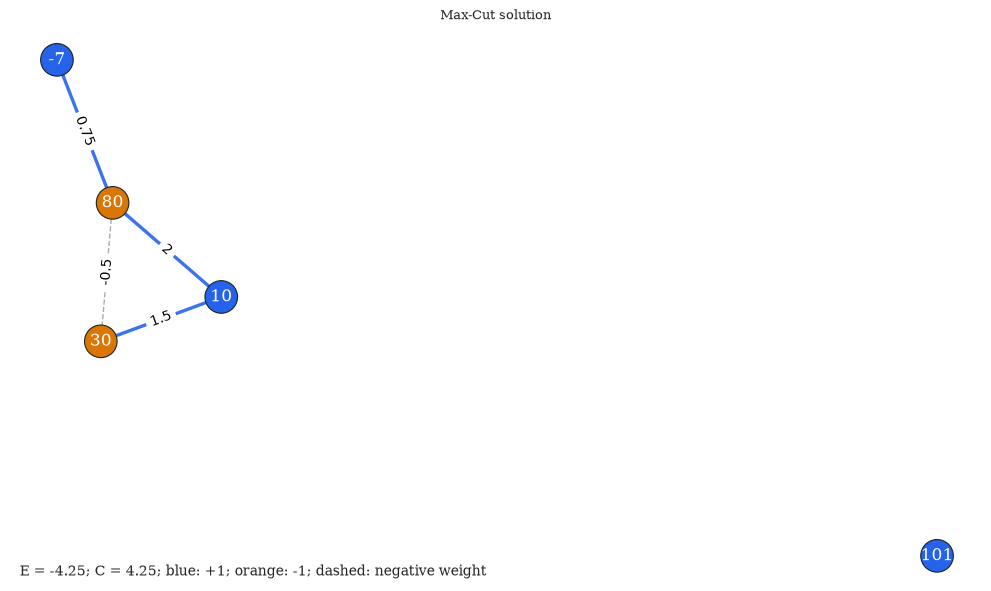

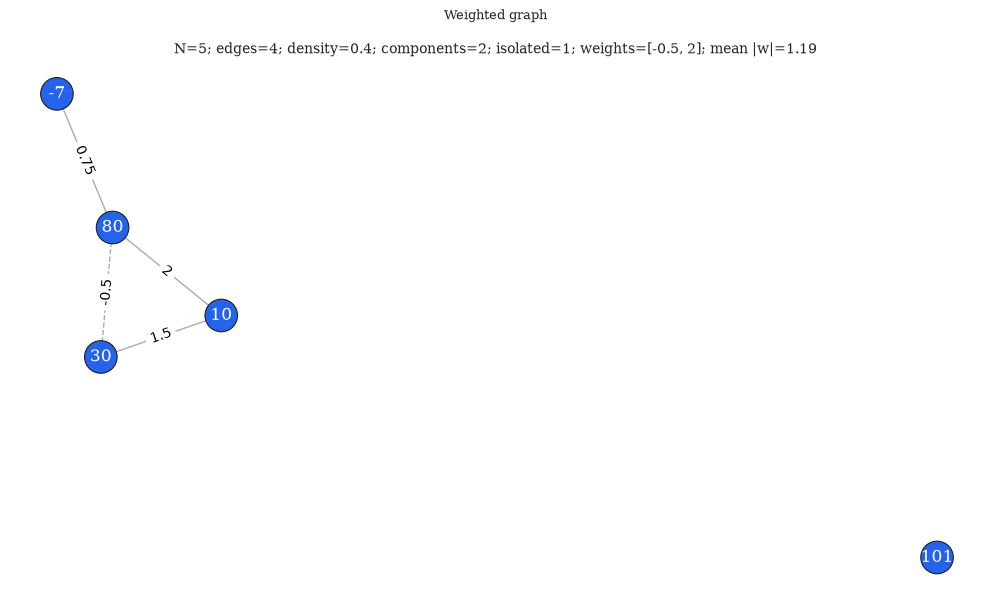

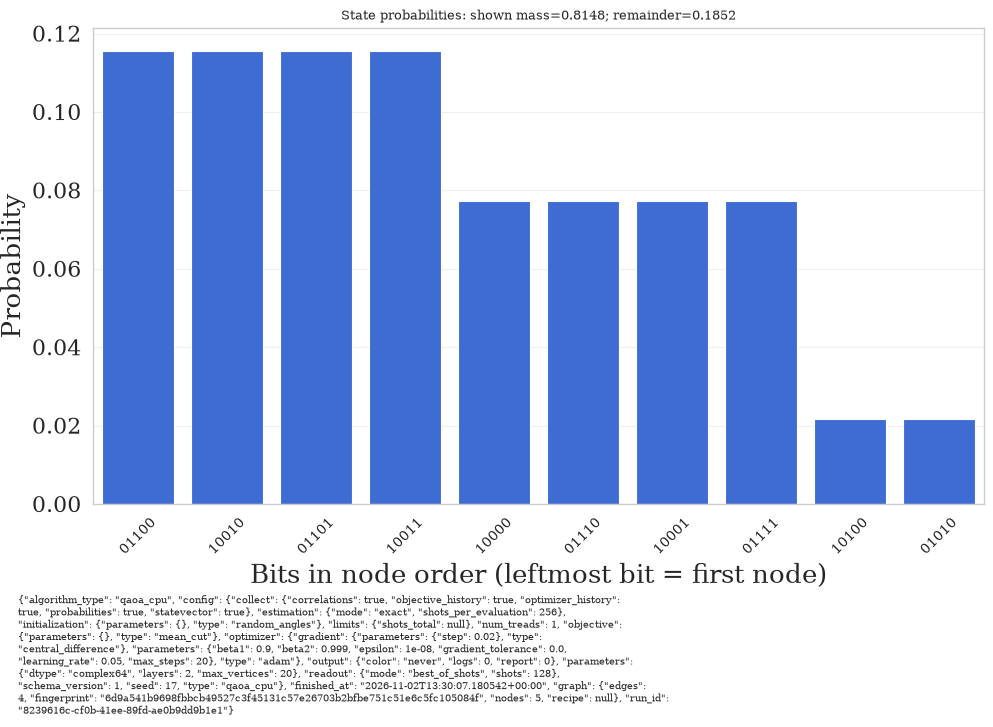

Tool result fields: ('schema_version', 'algorithm_type', 'package_version', 'status', 'finished_at', 'config', 'source', 'graph', 'plot_data')
Plot export: ['probability_plot.pdf', 'probability_plot.json']


In [12]:
figure = tools.plot_graph_solution(loaded, config={'style': style})
display(figure)
plt.close(figure)
figure = tools.plot_graph_info(loaded, {'style': style})
display(figure)
plt.close(figure)

figure = tools.plot_probabilities(loaded, {
    'style': style, 'selection': {'top_k': 10},
    'save': {'path': str(output_dir), 'filename': 'probability_plot', 'format': 'pdf',
             'DPI': 250, 'metadata': True, 'atts': ['source', 'plot_data'],
             'makedir': True, 'savedir': True},
})
display(figure)
print('Tool result fields:', figure.qa_record.field_names)
print('Plot export:', [path.name for path in figure.qa_saved_files.files])
plt.close(figure)

## 12. p=1 landscape map

The scanner computes the map without optimization, on an explicit γ and β grid. By default the color shows `optimizer_loss`, which is $\langle E\rangle$ for Mean Cut. Array rows are β, columns are γ. The γ window is chosen by the researcher: with arbitrary real weights no universal period is assumed.

The map is saved as a source array so the styling can later be changed without recomputation. An interactive three-dimensional HTML view is still on the migration plan.

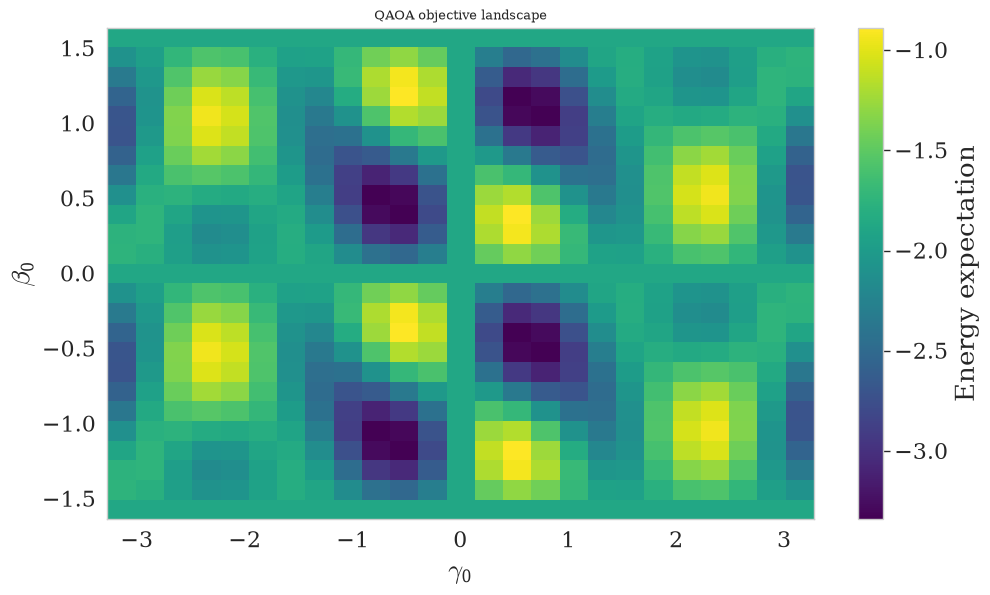

Grid points: 625
Minimum grid energy expectation: -3.339861928248701


In [13]:
landscape = tools.scan_landscape(graph, {
    'gamma': np.linspace(-np.pi, np.pi, 25).tolist(),
    'beta': np.linspace(-np.pi/2, np.pi/2, 25).tolist(),
    'objective': {'type': 'mean_cut', 'parameters': {}},
    'quantity': 'optimizer_loss',
    'save': {'path': str(output_dir), 'filename': 'energy_map',
             'atts': ['gamma', 'beta'], 'save_original_data': ['values'],
             'makedir': True, 'savedir': True},
})
assert landscape.values.shape == (25, 25)
map_files = output_dir / 'energy_map' / 'energy_map.json'
loaded_map = tools.load_result(map_files, load_original_data=True)
np.testing.assert_array_equal(loaded_map.values, landscape.values)
figure = tools.plot_landscape(loaded_map, {
    'style': style,
    'save': {'path': str(output_dir), 'filename': 'energy_landscape', 'format': 'png',
             'DPI': 250, 'metadata': False, 'makedir': True},
})
display(figure)
plt.close(figure)
print('Grid points:', landscape.resources['grid_points'])
print('Minimum grid energy expectation:', float(landscape.values.min()))

## 13. Explicit errors and stage boundaries

Uncollected history or probability is not recomputed on a plot's request. Existing files are protected. `num_treads>1`, GPU types and checkpoint/resume are still rejected. This makes it possible to distinguish a working mode from one not yet ported.

In [14]:
try:
    tools.save_result(first_record, export_config)
except FileExistsError:
    print('Expected: existing files are protected.')
else:
    raise AssertionError('The export must be exclusive.')

for name, action in [
    ('Parallel CPU', lambda: ExactCPU().solve(graph, num_treads=2)),
    ('Checkpoint', lambda: QAOACPU({'checkpoint': {'enabled': True}})),
    ('GPU type', lambda: SolverFactory.from_config({'type': 'qaoa_gpu'})),
    ('Missing probabilities', lambda: tools.plot_probabilities(reference)),
]:
    try:
        action()
    except ValueError as error:
        print(name + ':', error)
    else:
        raise AssertionError(name + ' must be rejected in this milestone.')

Expected: existing files are protected.
Parallel CPU: Parallel CPU execution is not implemented in this milestone; use num_treads=1.
Checkpoint: Checkpoint/resume is planned, not implemented in 0.1.0a4.
GPU type: Solver 'qaoa_gpu' is not implemented in 0.1.0a4. Available: ('exact_cpu', 'qaoa_cpu', 'rqaoa_cpu')
Missing probabilities: No probabilities were collected. Enable collect.probabilities before solve().


## 14. Running from the module and reference

```bash
python -m QA_max_cut_lib.solvers.exact_cpu --report 1 --logs 0
python -m QA_max_cut_lib.solvers.qaoa_cpu --graph configs/graphs/complete_signed_7.json --config configs/solvers/qaoa_cpu.json --report 2 --logs 1
python -m QA_max_cut_lib.solvers.rqaoa_cpu --graph configs/graphs/complete_signed_7.json --config configs/solvers/rqaoa_analytic_p1_cpu.json --report 2 --logs 1
```

Report and log levels are independent: 0 — off, 1 — brief, 2 — detailed. Color is controlled by `output.color=auto|always|never`.

The full table of arguments and attributes is in `docs/API.md`. Formula derivations, sign conventions and differences between estimates are in `docs/MATHEMATICS.md`. Base RQAOA and analytic p=1 are already implemented; later stages provide LS-RQAOA, independent CPU/GPU algorithms, the shared benchmark, a thread profiler, checkpoints and reduction trajectories; their state is recorded in `docs/MIGRATION_STATUS.md`.

## RQAOA on CPU

The base `RQAOACPU` trains QAOA on the current graph, obtains physical
correlations, selects a pair and applies an exact constraint. `ExactCPU` solves
the remainder; the original spins are reconstructed.

A full walkthrough with the reduction table, shot mode, budget stop and saving
is in [04_rqaoa_cpu.ipynb](04_rqaoa_cpu.ipynb). The full state vector limits the
size of the source graph; the 1000-vertex target does not apply to this
implementation.


In [15]:
from QA_max_cut_lib import SolverFactory, WeightedGraph, tools
import math as _math

rqaoa_graph = WeightedGraph(
    [(10, 20, 1.5), (20, 30, -0.5), (10, 30, 2.0)],
    nodes=[10, 20, 30, 101],
)
rqaoa_config = tools.load_json(root / 'configs/solvers/rqaoa_cpu.json')
rqaoa_config['parameters'] = {'finish_at': 2, 'max_reductions': None}
rqaoa_config['correlation_source']['optimizer']['parameters']['max_steps'] = 2
rqaoa_config['output'] = {'report': 0, 'logs': 0, 'color': 'never'}
rqaoa = SolverFactory.from_config(rqaoa_config)
rqaoa_solution = rqaoa.solve(rqaoa_graph)
assert set(rqaoa_solution) == set(rqaoa_graph.nodes)
assert _math.isclose(rqaoa.cut_value, rqaoa_graph.cut_value(rqaoa_solution))
print('RQAOA cut:', rqaoa.cut_value,
      'reductions:', rqaoa.reductions_completed,
      'source:', rqaoa.solution_source)


RQAOA cut: 3.5 reductions: 2 source: zero_interaction_residual


## Analytic p=1

The `qaoa_analytic_p1_cpu` source computes the mean cut and physical ZZ
correlations without a `2**N` state vector. It supports only Mean Cut, `p=1`
and exact moments; shots and the other criteria remain with the statevector
source. A full example with a gamma profile and a 30-vertex problem is in
[05_analytic_p1_rqaoa.ipynb](05_analytic_p1_rqaoa.ipynb).


In [16]:
from QA_max_cut_lib import SolverFactory, WeightedGraph, tools
import math as _math

analytic_graph = WeightedGraph(
    [(10, 20, 1.5), (20, 30, -0.5), (10, 30, 2.0)],
    nodes=[10, 20, 30, 101],
)
analytic_config = tools.load_json(root / 'configs/solvers/rqaoa_analytic_p1_cpu.json')
analytic_config.pop('save', None)
analytic_config['parameters'] = {'finish_at': 2, 'max_reductions': None}
analytic_config['correlation_source']['optimizer']['parameters']['points'] = 9
analytic_config['output'] = {'report': 0, 'logs': 0, 'color': 'never'}
analytic = SolverFactory.from_config(analytic_config)
analytic_solution = analytic.solve(analytic_graph)
assert analytic.resources['shots_used'] == 0
assert _math.isclose(analytic.cut_value, analytic_graph.cut_value(analytic_solution))
print('Analytic RQAOA cut:', analytic.cut_value,
      'reductions:', analytic.reductions_completed,
      'shots:', analytic.resources['shots_used'])


Analytic RQAOA cut: 3.5 reductions: 2 shots: 0
